# 01 — Exploratory Data Analysis: MVA Raw Inputs

**Scope:** FASTQ quality (sampled read pass), provided call-set (VCF) structure
and statistics, and the curated HPO phenotype terms. This is the raw-input EDA
that feeds `notebooks/02_variant_prioritization` and the Track 1 write-up.

**Data provenance & privacy:** all inputs are controlled-access patient data
(WCG IRB #20252010; MVA hackathon dataset). Everything below is *aggregate*
only — no per-variant row dumps, no read headers, no clinical narrative from
the phenotype document (the 8 curated HPO IDs in `config/hpo_terms.yaml` are
the committed, de-identified phenotypic input).

**Runtime:** first run ~1–2 min (50k-read FASTQ sampling ≈5 s + one streaming
pass over the 5M-record VCF, cached to `results/eda/vcf_stats.json`);
re-runs <10 s from cache.

Regenerate this notebook from the paired percent script and execute it:

```bash
uv run jupytext --to ipynb notebooks/01_exploratory.py
uv run jupyter nbconvert --to notebook --execute --inplace \
  --ExecutePreprocessor.timeout=900 notebooks/01_exploratory.ipynb
```

## 1. Setup

Repo-relative paths (robust to being executed from either the repo root or
`notebooks/`), pipeline config, plotting style, and environment versions.

In [1]:
import json
import re
import subprocess
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from cyvcf2 import VCF

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

import builtins

if hasattr(builtins, "display"):
    display = builtins.display
else:  # running as a plain script (Jupyter injects display into builtins)

    def display(x):
        print(x if isinstance(x, str) else x.to_string(index=False))


def find_repo_root(start: Path) -> Path:
    """Walk up from `start` until pyproject.toml marks the repo root."""
    for p in [start, *start.parents]:
        if (p / "pyproject.toml").exists() and (p / "src").exists():
            return p
    return start


ROOT = find_repo_root(Path.cwd())
RAW = ROOT / "data" / "raw"
FASTQ_DIR = RAW / "fastq"
VCF_PATH = RAW / "calls" / "WGS_EX2312012_HGWCNDSX7.vcf.gz"
PHENO_DOC = RAW / "phenotype" / "Challenge_Clinical_Phenotype_1.docx"
HPO_YAML = ROOT / "config" / "hpo_terms.yaml"
CONFIG_YAML = ROOT / "config" / "example_config.yaml"
EDA_CACHE_DIR = ROOT / "results" / "eda"
EDA_CACHE = EDA_CACHE_DIR / "vcf_stats.json"

print(f"repo root : {ROOT}")
print(f"python    : {sys.version.split()[0]}")
print(f"pandas    : {pd.__version__} | numpy {np.__version__} | cyvcf2 {__import__('cyvcf2').__version__}")

git_sha = subprocess.run(
    ["git", "rev-parse", "--short", "HEAD"], cwd=ROOT,
    capture_output=True, text=True, check=False,
)
print(f"git HEAD  : {git_sha.stdout.strip() or 'unknown'}")

config = yaml.safe_load(CONFIG_YAML.read_text())
print(f"config    : AF<{config['gnomad_af_threshold']}, CADD>={config['cadd_threshold']}, "
      f"weights pheno/path = {config['phenotype_weight']}/{config['pathogenicity_weight']}")

repo root : /home/pab1s/Projects/mva-variant-prioritization
python    : 3.12.12
pandas    : 3.0.5 | numpy 2.5.2 | cyvcf2 0.34.0
git HEAD  : 921aa2f
config    : AF<0.01, CADD>=15, weights pheno/path = 0.6/0.4


## 2. Data inventory

What exists on disk (sizes only — `data/` and `results/` are gitignored and
never committed).

In [2]:
def human(n: float) -> str:
    for unit in ("B", "KB", "MB", "GB", "TB"):
        if n < 1024 or unit == "TB":
            return f"{n:.1f} {unit}"
        n /= 1024


inventory = []
for label, p in [
    ("FASTQ (8 files, 4 lanes x R1/R2)", FASTQ_DIR),
    ("VCF (provided Sentieon call set)", VCF_PATH),
    ("VCF index", Path(str(VCF_PATH) + ".tbi")),
    ("Phenotype doc (confidential)", PHENO_DOC),
    ("HPO terms (committed)", HPO_YAML),
    ("Reference GRCh38", ROOT / "data" / "references" / "GRCh38.fa"),
    ("VEP cache", ROOT / "data" / "vep_cache"),
    ("CADD v1.7 whole-genome SNVs", ROOT / "data" / "cadd" / "whole_genome_SNVs.tsv.gz"),
    ("VEP-annotated interim VCF", ROOT / "data" / "interim" / "full.vep.vcf.gz"),
    ("ClinVar GRCh38 (labels)", ROOT / "data" / "clinvar" / "clinvar.vcf.gz"),
    ("HPO gene-phenotype map", ROOT / "data" / "hpo" / "genes_to_phenotype.txt"),
    ("HPO ontology (hp.obo)", ROOT / "data" / "hpo" / "hp.obo"),
]:
    if p.is_dir():
        size = sum(f.stat().st_size for f in p.rglob("*") if f.is_file())
        n_files = sum(1 for f in p.rglob("*") if f.is_file())
        exists, detail = p.exists(), f"{n_files} files"
    elif p.is_file():
        size, exists, detail = p.stat().st_size, True, p.name
    elif p.parent.exists() and str(p).endswith((".gz", ".docx")):
        # e.g. reference delivered as .fa.gz only — report absence honestly
        size, exists, detail = 0, False, "MISSING"
    else:
        size, exists, detail = 0, False, "MISSING"
    inventory.append({"item": label, "path": str(p.relative_to(ROOT)), "present": exists,
                      "size": human(size) if exists else "-", "detail": detail})

inv_df = pd.DataFrame(inventory)
display(inv_df)

fastqs = sorted(FASTQ_DIR.glob("*.fastq.gz"))
print(f"\nFASTQ files found: {len(fastqs)}")
assert VCF_PATH.exists(), f"VCF missing: {VCF_PATH}"
assert len(fastqs) == 8, f"expected 8 FASTQs, found {len(fastqs)}"

,item,path,present,size,detail
0,"FASTQ (8 files, 4 lanes x R1/R2)",data/raw/fastq,True,78.9 GB,8 files
1,VCF (provided Sentieon call set),data/raw/calls/WGS_EX2312012_HGWCNDSX7.vcf.gz,True,300.6 MB,WGS_EX2312012_HGWCNDSX7.vcf.gz
2,VCF index,data/raw/calls/WGS_EX2312012_HGWCNDSX7.vcf.gz.tbi,True,1.6 MB,WGS_EX2312012_HGWCNDSX7.vcf.gz.tbi
3,Phenotype doc (confidential),data/raw/phenotype/Challenge_Clinical_Phenotyp...,True,16.5 KB,Challenge_Clinical_Phenotype_1.docx
4,HPO terms (committed),config/hpo_terms.yaml,True,1.2 KB,hpo_terms.yaml
5,Reference GRCh38,data/references/GRCh38.fa,True,2.9 GB,GRCh38.fa
6,VEP cache,data/vep_cache,True,15.7 GB,3828 files
7,CADD v1.7 whole-genome SNVs,data/cadd/whole_genome_SNVs.tsv.gz,True,81.5 GB,whole_genome_SNVs.tsv.gz
8,VEP-annotated interim VCF,data/interim/full.vep.vcf.gz,True,378.2 MB,full.vep.vcf.gz
9,ClinVar GRCh38 (labels),data/clinvar/clinvar.vcf.gz,True,191.4 MB,clinvar.vcf.gz



FASTQ files found: 8


## 3. FASTQ quality (sampled read pass)

The pipeline's original QC JSONs (`results/qc/*.json`) were removed in a
results cleanup, so this notebook computes QC directly from the source reads:
a **deterministic 50k-read sample per file** (first 50k records — FASTQ files
are lane-shuffled fragments, so the head is representative of the run).
Full per-base FastQC on the ~83 GB of raw reads is out of scope.

In [3]:
N_SAMPLE_READS = 50_000


def sample_fastq(path: Path, n_reads: int = N_SAMPLE_READS) -> dict:
    """GC%, mean read length and Phred stats from the first `n_reads` records."""
    import gzip

    n = bases = gc = q_sum = q_bases = q30 = 0
    lens: Counter = Counter()
    with gzip.open(path, "rt") as fh:
        while n < n_reads:
            if not fh.readline():
                break
            seq = fh.readline().strip()
            fh.readline()
            qual = fh.readline().strip()
            if not qual:
                break
            n += 1
            bases += len(seq)
            lens[len(seq)] += 1
            gc += sum(seq.count(b) for b in "GCgc")
            qs = [ord(c) - 33 for c in qual]
            q_sum += sum(qs)
            q_bases += len(qs)
            q30 += sum(1 for q in qs if q >= 30)
    return {
        "reads_sampled": n,
        "avg_len": bases / n if n else np.nan,
        "modal_len": lens.most_common(1)[0][0] if lens else np.nan,
        "gc_pct": 100 * gc / bases if bases else np.nan,
        "mean_phred": q_sum / q_bases if q_bases else np.nan,
        "pct_q30": 100 * q30 / q_bases if q_bases else np.nan,
    }


qc_rows = []
for fq in sorted(FASTQ_DIR.glob("*.fastq.gz")):
    m = re.search(r"_(S\d+)_(L\d+)_(R[12])_", fq.name)
    row = {"lane": m.group(2) if m else "?", "read": m.group(3) if m else "?"}
    row.update(sample_fastq(fq))
    row["file_mb"] = round(fq.stat().st_size / 1e6, 1)
    qc_rows.append(row)

qc = pd.DataFrame(qc_rows).sort_values(["lane", "read"]).reset_index(drop=True)
display(qc)

print(f"reads sampled per file : {N_SAMPLE_READS:,}")
print(f"read length            : {sorted(qc['modal_len'].unique())} bp "
      f"(mean {qc['avg_len'].min():.1f}–{qc['avg_len'].max():.1f})")
print(f"GC%                    : {qc['gc_pct'].min():.1f} – {qc['gc_pct'].max():.1f} "
      f"(human WGS expectation ~41%)")
print(f"mean Phred             : {qc['mean_phred'].min():.1f} – {qc['mean_phred'].max():.1f}")
print(f"% bases >= Q30         : {qc['pct_q30'].min():.1f} – {qc['pct_q30'].max():.1f}")

,lane,read,reads_sampled,avg_len,modal_len,gc_pct,mean_phred,pct_q30,file_mb
0,L001,R1,50000,149.0,149,41.320953,35.746408,92.793799,10467.1
1,L001,R2,50000,149.0,149,41.654201,35.218710,90.085705,11035.9
2,L002,R1,50000,149.0,149,41.114242,35.615653,92.134054,10375.8
3,L002,R2,50000,149.0,149,41.366242,35.177656,89.927584,10911.1
4,L003,R1,50000,149.0,149,41.146497,35.494104,91.443611,10195.7
5,L003,R2,50000,149.0,149,41.292940,35.078604,89.422322,10621.4
6,L004,R1,50000,149.0,149,41.168859,35.569172,91.858362,10306.4
7,L004,R2,50000,149.0,149,41.356966,35.136067,89.698671,10755.1


reads sampled per file : 50,000
read length            : [np.int64(149)] bp (mean 149.0–149.0)
GC%                    : 41.1 – 41.7 (human WGS expectation ~41%)
mean Phred             : 35.1 – 35.7
% bases >= Q30         : 89.4 – 92.8


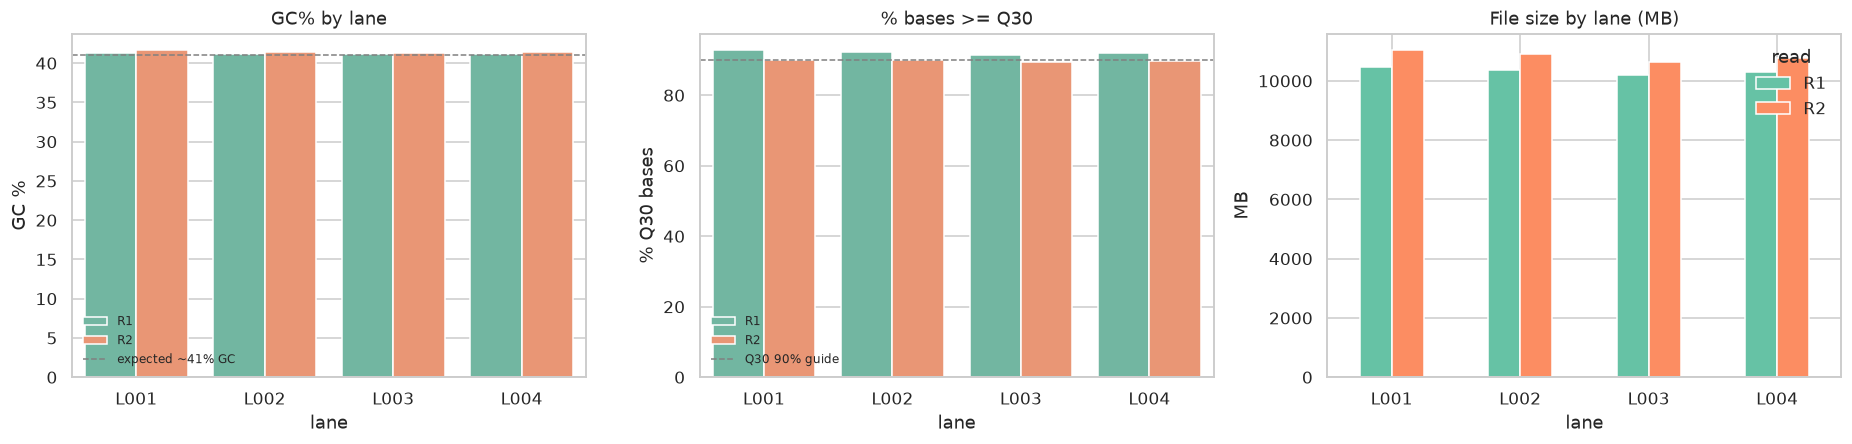

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
sns.barplot(data=qc, x="lane", y="gc_pct", hue="read", ax=axes[0], palette="Set2")
axes[0].axhline(41.0, ls="--", c="grey", lw=1, label="expected ~41% GC")
axes[0].set_title("GC% by lane")
axes[0].set_ylabel("GC %")
axes[0].legend(frameon=False, fontsize=8)

sns.barplot(data=qc, x="lane", y="pct_q30", hue="read", ax=axes[1], palette="Set2")
axes[1].axhline(90.0, ls="--", c="grey", lw=1, label="Q30 90% guide")
axes[1].set_title("% bases >= Q30")
axes[1].set_ylabel("% Q30 bases")
axes[1].legend(frameon=False, fontsize=8)

qc.pivot(index="lane", columns="read", values="file_mb").plot.bar(
    ax=axes[2], color=["#66c2a5", "#fc8d62"])
axes[2].set_title("File size by lane (MB)")
axes[2].set_ylabel("MB")
axes[2].tick_params(axis="x", rotation=0)
axes[2].legend(frameon=False, title="read")

plt.tight_layout()
plt.show()

**Finding:** GC is uniformly ~41.1–41.7% across all 8 lane/read files, mean
Phred is 35.1–35.7 with ~89–93% of bases at Q30 (R2 dips slightly below R1,
as always) → the run is clean, no lane or contamination anomaly, and no file
is truncated (R1/R2 sizes balance within each lane). Trimming/adapter work is
unlikely to change downstream variant quality materially.

## 4. VCF header: caller, reference, annotation surface

What the provided call set is, and — critically — what it *lacks*.

In [5]:
vcf = VCF(str(VCF_PATH))
header = vcf.raw_header

def header_tags(prefix: str) -> list[str]:
    return re.findall(rf"^##{prefix}=<ID=([^,>]+)", header, flags=re.MULTILINE)

caller = re.search(r"##SentieonCommandLine\.Haplotyper=<[^>]*?Version=\"([^\"]+)\"", header)
gatk = re.search(r'##GATKCommandLine=<ID=VariantFiltration,.*?Version="([^"]+)"', header)
# Prefer the informative assembly name (GCA_000001405.15 = GRCh38 no-alt)
# over the generic `refGenome/genome.fasta` placeholder that appears first.
ref_cands = re.findall(r"(GCA_\d+\.\d+\S*\.fasta|refGenome/\S+\.fasta)", header)
ref_match = next((c for c in ref_cands if "GCA_" in c), ref_cands[0] if ref_cands else None)
contigs = header_tags("contig")

print(f"records expected : 5,012,204 (docs) | samples: {vcf.samples}")
print(f"caller           : Sentieon Haplotyper {caller.group(1) if caller else '?'}")
print(f"filtration       : GATK VariantFiltration {gatk.group(1) if gatk else '?'}")
print(f"reference        : {ref_match.split('/')[-1] if ref_match else '?'}")
print(f"contigs in header: {len(contigs)}  (primary 1-22,X,Y,M + "
      f"{sum(1 for c in contigs if not re.fullmatch(r'([1-9]|1[0-9]|2[0-2]|X|Y|M)', c))} decoy/random/HLA)")
print(f"FILTER definitions: {header_tags('FILTER')}")
print(f"INFO fields      : {header_tags('INFO')}")
print(f"FORMAT fields    : {header_tags('FORMAT')}")

has_csq = "##INFO=<ID=CSQ" in header
has_gnomad = "gnomAD" in header
has_clinvar = "ClinVar" in header or "CLNSIG" in header
print(f"\nannotation present?  CSQ/VEP: {has_csq} | gnomAD: {has_gnomad} | ClinVar: {has_clinvar}")
assert not has_csq and not has_gnomad, "header changed — revisit the annotation-gap finding"

# The annotation layer now exists as an interim product (VEP v113, built 2026-10-22):
INTERIM_VEP = ROOT / "data" / "interim" / "full.vep.vcf.gz"
interim_vcf = VCF(str(INTERIM_VEP))  # header-only open, no record read
interim_csq = "##INFO=<ID=CSQ" in interim_vcf.raw_header
csq_desc = re.search(r'##INFO=<ID=CSQ,[^>]*?Description="([^"]+)"', interim_vcf.raw_header)
csq_fields = csq_desc.group(1).split("Format: ")[1].split("|") if csq_desc else []
print(f"interim annotated VCF : {INTERIM_VEP.relative_to(ROOT)} "
      f"({INTERIM_VEP.stat().st_size / 1e6:.0f} MB)")
print(f"  CSQ present: {interim_csq} | gnomADe_AF in CSQ: {'gnomADe_AF' in csq_fields} | "
      f"CLIN_SIG in CSQ: {'CLIN_SIG' in csq_fields} | {len(csq_fields)} CSQ subfields")
assert interim_csq and "gnomADe_AF" in csq_fields

records expected : 5,012,204 (docs) | samples: ['WGS_EX2312012']
caller           : Sentieon Haplotyper sentieon-genomics-202308.02
filtration       : GATK VariantFiltration 4.2.4.0
reference        : GCA_000001405.15_GRCh38_no_alt_analysis_set_plus_hs38d1_maskedGRC_exclusions_v2_no_chr.fasta
contigs in header: 2580  (primary 1-22,X,Y,M + 2555 decoy/random/HLA)
FILTER definitions: ['PASS', 'FS60', 'LowQual', 'MQ40', 'MQRankSum-12.5', 'QD2', 'RPRS-8']
INFO fields      : ['AC', 'AF', 'AN', 'BaseQRankSum', 'ClippingRankSum', 'DB', 'DP', 'ExcessHet', 'FS', 'InbreedingCoeff', 'MLEAC', 'MLEAF', 'MQ', 'MQRankSum', 'QD', 'ReadPosRankSum', 'SOR']
FORMAT fields    : ['AD', 'DP', 'GQ', 'GT', 'PGT', 'PID', 'PL']

annotation present?  CSQ/VEP: False | gnomAD: False | ClinVar: False
interim annotated VCF : data/interim/full.vep.vcf.gz (397 MB)
  CSQ present: True | gnomADe_AF in CSQ: True | CLIN_SIG in CSQ: True | 41 CSQ subfields


**Finding — the annotation gap is *in the raw input only*, and is now bridged:**
the provided call set carries *no* VEP `CSQ` consequences, *no* population
frequencies (gnomAD), *no* ClinVar, and no pathogenicity scores — raw INFO is
limited to GATK/Sentieon call-quality metrics (`QD`, `MQ`, `FS`, `DP`,
`AC/AF/AN`, dbSNP `DB` flag). Anything gene-level or rarity-based must come
from an annotation step. That step has since been run: **`data/interim/
full.vep.vcf.gz`** is VEP v113 with a 41-subfield `CSQ` that includes
`gnomADe_AF`, `CLIN_SIG` (ClinVar `--custom`), MANE/CANONICAL, HGVS — built
from the very same 5,012,204 records. The remaining gap versus a competitive
submission is **CADD** (`data/cadd/` present, `--plugin CADD` wired in
`src/annotation/vep.py` but not yet applied to the interim file) and
**gene↔phenotype mapping** (`data/hpo/genes_to_phenotype.txt` downloaded, not
yet consumed by `phenotype_score` — it currently defaults to neutral 0.5).

## 5. VCF record statistics (one streaming pass, cached)

Full pass over all 5,012,204 records with cyvcf2 (~30 s). Distributions are
accumulated on a deterministic 1-in-25 stride sample to keep the cache small.
Results are written to `results/eda/vcf_stats.json`; set `RECOMPUTE = True` to
refresh.

In [6]:
RECOMPUTE = False
STRIDE = 25  # 1-in-N records kept for numeric distributions (~200k points)

PRIMARIES = {str(i) for i in range(1, 23)} | {"X", "Y", "M", "MT"}
TRANSITIONS = {("A", "G"), ("G", "A"), ("C", "T"), ("T", "C")}
METRIC_BINS = {  # ranges chosen from a pilot sample; values clipped into last bin
    "QUAL": np.linspace(0, 2000, 81),
    "QD": np.linspace(0, 60, 61),
    "MQ": np.linspace(20, 61, 42),
    "DP": np.linspace(0, 200, 81),
}


def classify_variant(ref: str, alts: list[str]) -> str:
    if all(len(a) == 1 for a in alts) and len(ref) == 1:
        return "SNV"
    if all(len(a) == len(ref) for a in alts):
        return "MNP"
    if any(len(a) != len(ref) for a in alts):
        return "indel"
    return "other"


def classify_gt(a: int, b: int) -> str:
    if a < 0 or b < 0:
        return "missing"
    if a == b:
        return "hom_alt" if a > 0 else "hom_ref"
    return "het"


def scan_vcf(path: Path, stride: int) -> dict:
    """Single streaming pass → aggregate stats. No per-variant data retained."""
    vcf = VCF(str(path))
    chrom_counts: Counter = Counter()
    type_counts: Counter = Counter()
    filter_token_counts: Counter = Counter()
    filter_combo_counts: Counter = Counter()
    gt_counts: Counter = Counter()
    alt_counts: Counter = Counter()
    samples = {k: [] for k in METRIC_BINS}
    ti = tv = db_present = total = 0
    multiallelic = 0

    for v in vcf:
        total += 1
        chrom_counts[v.CHROM] += 1
        alts = v.ALT
        alt_counts[min(len(alts), 5)] += 1
        if len(alts) > 1:
            multiallelic += 1
        type_counts[classify_variant(v.REF, alts)] += 1

        # FILTER: count full combination + individual tokens
        filt = v.FILTER if v.FILTER else "PASS"
        filter_combo_counts[filt] += 1
        for tok in filt.split(";"):
            filter_token_counts[tok] += 1

        # genotype (single sample) — classify from genotypes, not gt_types
        a, b, _ = v.genotypes[0]
        gt_counts[classify_gt(a, b)] += 1

        # dbSNP membership
        if v.INFO.get("DB") is not None:
            db_present += 1

        # transition/transversion on biallelic SNVs
        if len(alts) == 1 and classify_variant(v.REF, alts) == "SNV":
            pair = (v.REF.upper(), alts[0].upper())
            if pair in TRANSITIONS:
                ti += 1
            else:
                tv += 1

        # stride sample for distributions
        if total % stride == 0:
            samples["QUAL"].append(v.QUAL)
            qd, mq, dp = v.INFO.get("QD"), v.INFO.get("MQ"), v.INFO.get("DP")
            samples["QD"].append(qd if qd is not None else np.nan)
            samples["MQ"].append(mq if mq is not None else np.nan)
            samples["DP"].append(dp if dp is not None else np.nan)

    hist = {}
    summary = {}
    for key, bins in METRIC_BINS.items():
        arr = np.asarray(samples[key], dtype=float)
        finite = arr[np.isfinite(arr)]
        counts, edges = np.histogram(finite, bins=bins)
        # tail beyond last edge, kept so plots can show overflow explicitly
        hist[key] = {"counts": counts.tolist(), "edges": [float(e) for e in edges],
                     "overflow": int((finite > bins[-1]).sum()),
                     "missing": int(arr.size - finite.size)}
        summary[key] = {"p01": float(np.percentile(finite, 1)),
                        "p50": float(np.percentile(finite, 50)),
                        "p99": float(np.percentile(finite, 99)),
                        "max": float(finite.max())}

    return {
        "total": total,
        "chrom_counts": dict(chrom_counts),
        "type_counts": dict(type_counts),
        "multiallelic": multiallelic,
        "alt_counts": {str(k): v for k, v in alt_counts.items()},
        "filter_token_counts": dict(filter_token_counts),
        "filter_combo_counts": dict(filter_combo_counts),
        "gt_counts": dict(gt_counts),
        "ti": ti, "tv": tv,
        "db_present": db_present,
        "hist": hist,
        "metric_summary": summary,
        "stride": stride,
    }


if EDA_CACHE.exists() and not RECOMPUTE:
    stats = json.loads(EDA_CACHE.read_text())
    print(f"loaded cache: {EDA_CACHE.relative_to(ROOT)} ({EDA_CACHE.stat().st_size // 1024} KB)")
else:
    print(f"scanning {VCF_PATH.name} (full pass, stride={STRIDE}) ...")
    stats = scan_vcf(VCF_PATH, STRIDE)
    EDA_CACHE_DIR.mkdir(parents=True, exist_ok=True)
    EDA_CACHE.write_text(json.dumps(stats))
    print(f"cached → {EDA_CACHE.relative_to(ROOT)} ({EDA_CACHE.stat().st_size // 1024} KB)")

EXPECTED_TOTAL = 5_012_204
print(f"records scanned : {stats['total']:,} (docs: {EXPECTED_TOTAL:,}) → "
      f"{'MATCH' if stats['total'] == EXPECTED_TOTAL else 'MISMATCH'}")

loaded cache: results/eda/vcf_stats.json (52 KB)
records scanned : 5,012,204 (docs: 5,012,204) → MATCH


In [7]:
types = pd.Series(stats["type_counts"]).sort_values(ascending=False)
gts = pd.Series(stats["gt_counts"])
filters = pd.Series(stats["filter_token_counts"]).sort_values(ascending=False)
combos = pd.Series(stats["filter_combo_counts"]).sort_values(ascending=False)
titv = stats["ti"] / stats["tv"] if stats["tv"] else float("nan")

summary_tbl = pd.DataFrame([
    ("total records", f"{stats['total']:,}"),
    ("SNV / indel / MNP", f"{types.get('SNV', 0):,} / {types.get('indel', 0):,} / {types.get('MNP', 0):,}"),
    ("multiallelic sites", f"{stats['multiallelic']:,} ({stats['multiallelic']/stats['total']:.2%})"),
    ("Ti/Tv (biallelic SNVs)", f"{titv:.3f}  (WGS expectation ~2.0–2.1)"),
    ("dbSNP-overlapping", f"{stats['db_present']:,} ({stats['db_present']/stats['total']:.1%})"),
    ("PASS", f"{combos.get('PASS', 0):,} ({combos.get('PASS', 0)/stats['total']:.1%})"),
    ("het / hom_alt", (f"{gts.get('het', 0):,} / {gts.get('hom_alt', 0):,} "
                       f"(ratio {gts.get('het', 0)/max(gts.get('hom_alt', 1), 1):.2f})")),
    ("hom_ref / missing GT", f"{gts.get('hom_ref', 0):,} / {gts.get('missing', 0):,}"),
])
display(summary_tbl)

,0,1
0,total records,"5,012,204"
1,SNV / indel / MNP,"4,082,023 / 930,181 / 0"
2,multiallelic sites,"66,860 (1.33%)"
3,Ti/Tv (biallelic SNVs),1.946 (WGS expectation ~2.0–2.1)
4,dbSNP-overlapping,"4,408,823 (88.0%)"
5,PASS,"4,740,790 (94.6%)"
6,het / hom_alt,"3,113,937 / 1,898,267 (ratio 1.64)"
7,hom_ref / missing GT,0 / 0


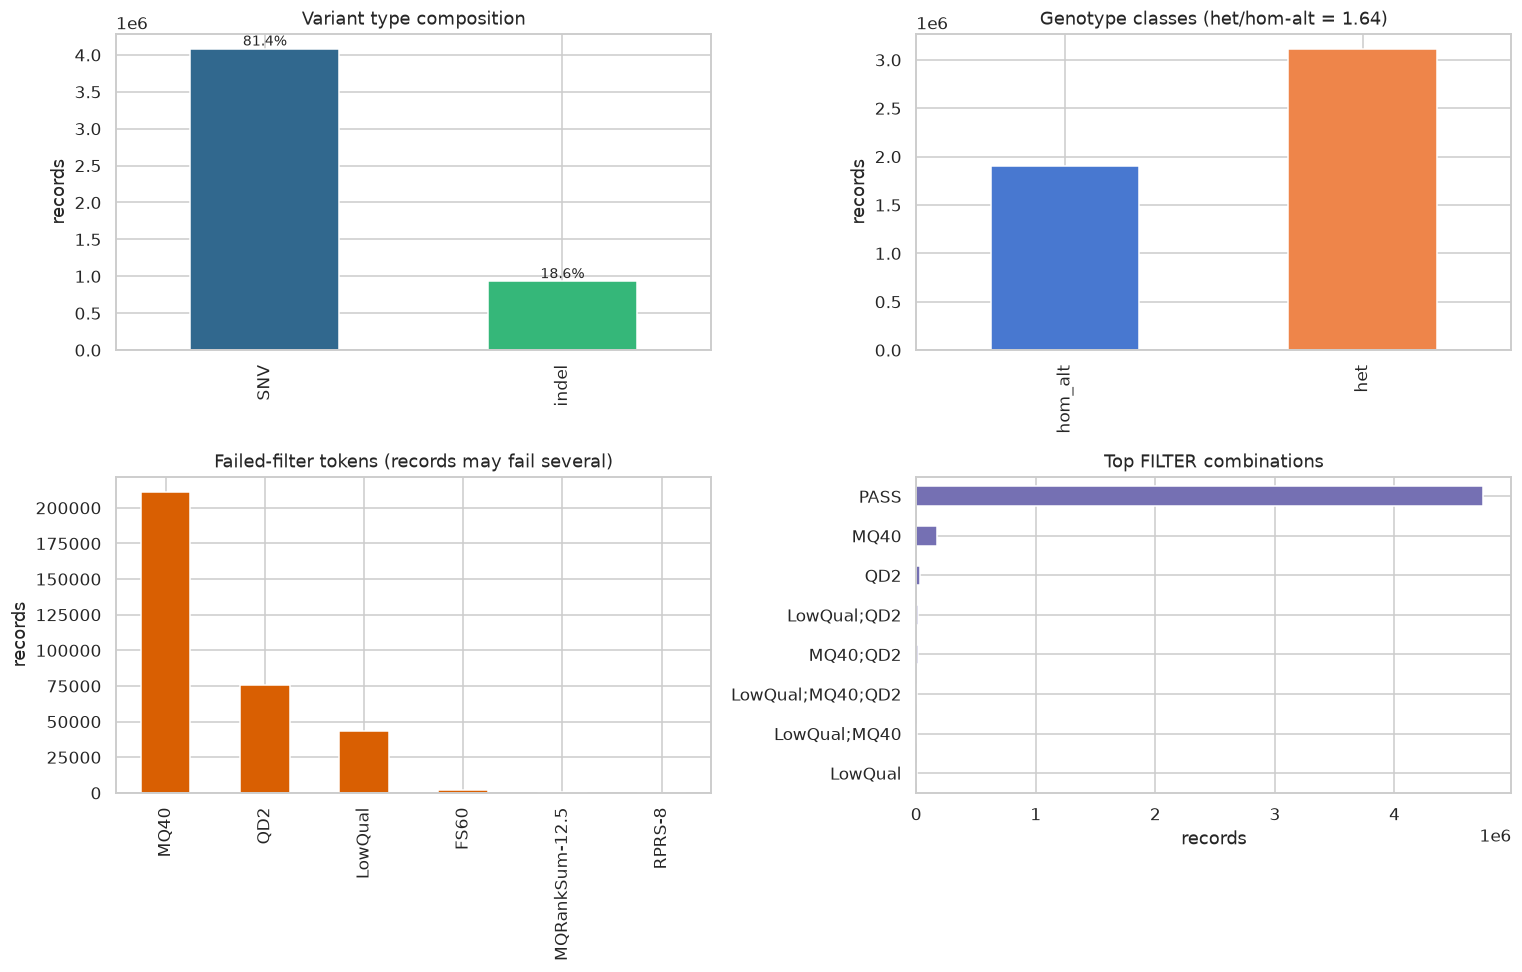

Top FILTER combinations:


,records
PASS,4740790
MQ40,177522
QD2,35402
LowQual;QD2,17000
MQ40;QD2,12541
LowQual;MQ40;QD2,10240
LowQual;MQ40,9782
LowQual,6081


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

types.plot.bar(ax=axes[0, 0], color=sns.color_palette("viridis", len(types)))
axes[0, 0].set_title("Variant type composition")
axes[0, 0].set_ylabel("records")
for i, (k, v) in enumerate(types.items()):
    axes[0, 0].text(i, v, f"{v/stats['total']:.1%}", ha="center", va="bottom", fontsize=9)

gts.plot.bar(ax=axes[0, 1], color=sns.color_palette("muted", len(gts)))
axes[0, 1].set_title(f"Genotype classes (het/hom-alt = "
                     f"{gts.get('het',0)/max(gts.get('hom_alt',1),1):.2f})")
axes[0, 1].set_ylabel("records")

drop_pass = filters.drop(labels="PASS", errors="ignore")
drop_pass.plot.bar(ax=axes[1, 0], color="#d95f02")
axes[1, 0].set_title("Failed-filter tokens (records may fail several)")
axes[1, 0].set_ylabel("records")

combos.head(8).plot.barh(ax=axes[1, 1], color="#7570b3")
axes[1, 1].invert_yaxis()
axes[1, 1].set_title("Top FILTER combinations")
axes[1, 1].set_xlabel("records")

plt.tight_layout()
plt.show()

print("Top FILTER combinations:")
display(combos.head(8).to_frame("records"))

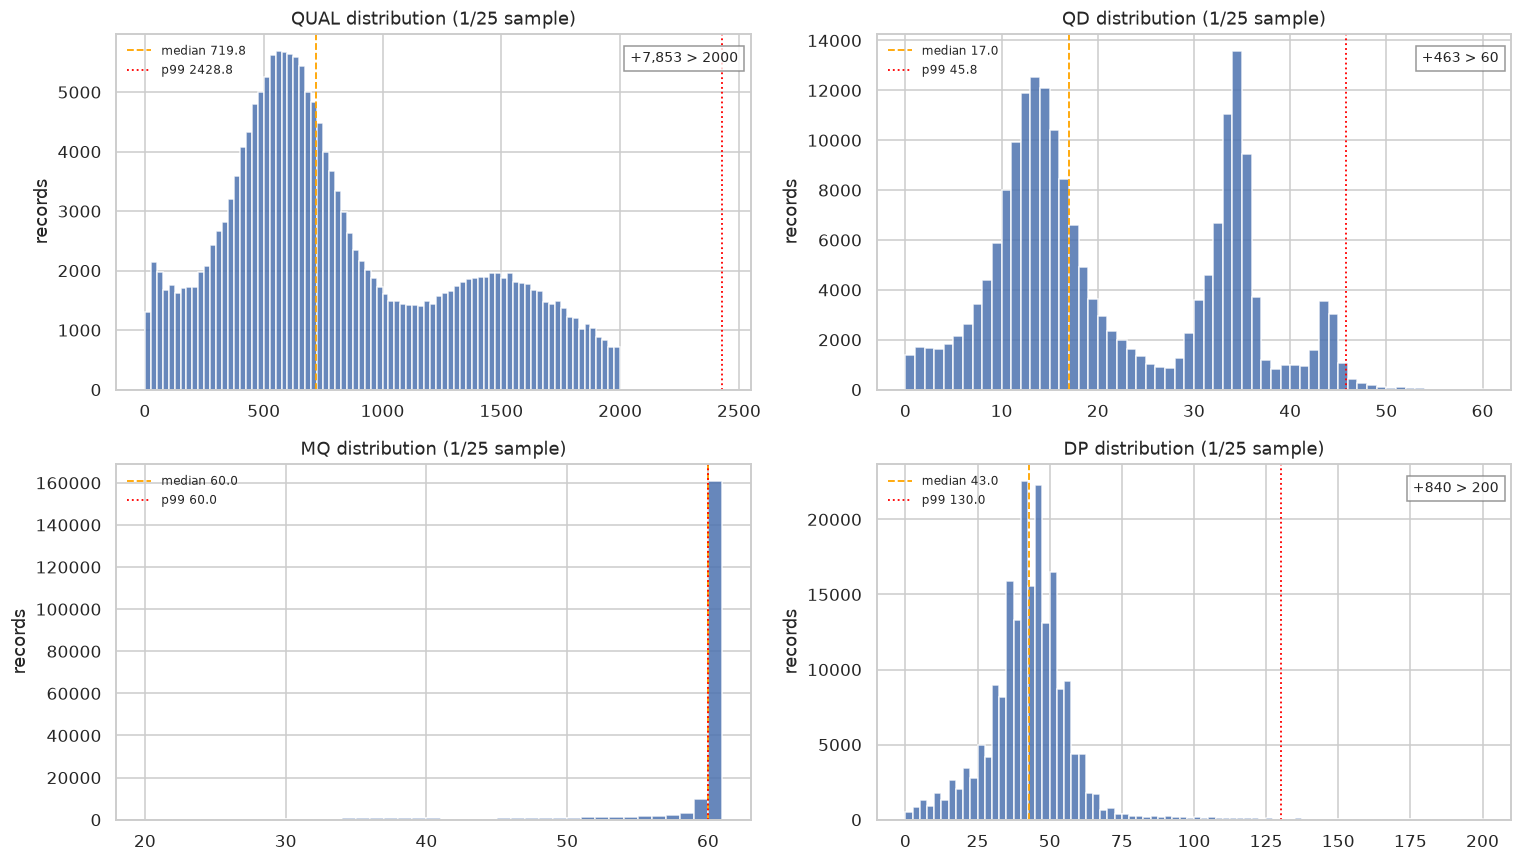

Metric summary (stride sample):


,p01,p50,p99,max
QUAL,33.7300,719.770020,2428.770020,853207.75000
QD,1.3500,17.040001,45.799999,2227.72998
MQ,28.8487,60.000000,60.000000,60.00000
DP,6.0000,43.000000,130.000000,20540.00000


In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (key, h) in zip(axes.flat, stats["hist"].items()):
    edges, counts = np.array(h["edges"]), np.array(h["counts"])
    centers = (edges[:-1] + edges[1:]) / 2
    width = np.diff(edges)
    ax.bar(centers, counts, width=width, color="#4c72b0", alpha=0.85)
    if h["overflow"]:
        ax.text(0.98, 0.95, f"+{h['overflow']:,} > {edges[-1]:.0f}",
                transform=ax.transAxes, ha="right", va="top", fontsize=9,
                bbox={"fc": "white", "ec": "grey", "alpha": 0.8})
    s = stats["metric_summary"][key]
    ax.axvline(s["p50"], color="orange", ls="--", lw=1.2, label=f"median {s['p50']:.1f}")
    ax.axvline(s["p99"], color="red", ls=":", lw=1.2, label=f"p99 {s['p99']:.1f}")
    ax.set_title(f"{key} distribution (1/{stats['stride']} sample)")
    ax.set_ylabel("records")
    ax.legend(frameon=False, fontsize=8)

plt.tight_layout()
plt.show()

print("Metric summary (stride sample):")
display(pd.DataFrame(stats["metric_summary"]).T)

**Sanity verdicts (call-set quality):**
- **Ti/Tv = 1.95** (computed below) — just below the textbook ~2.0–2.1
  whole-genome expectation, entirely normal for a clinical cohort call set →
  base-level substitution profile looks like a real genome, not artifacts.
- **het/hom-alt ratio 1.64** — inside the normal human ~1.6–2.0 range → no
  gross genotype-calling anomaly.
- **dbSNP overlap 88%** — the fraction of records already known common
  variation; the remaining ~12% is where novel/rare disease signal lives.
- `MQ` is capped at 60 (GATK ceiling) and `DP`/`QUAL` are long-tailed → the
  numeric features usable for ranking are **quality metrics only**, until
  annotation (Section 4's finding) is added.

## 6. Per-chromosome counts (index cross-check)

Counts straight from the `.tbi` index — instant, independent of the streaming
pass above.

In [10]:
out = subprocess.run(
    ["bcftools", "index", "-s", str(VCF_PATH)],
    capture_output=True, text=True, check=True,
)
idx_rows = [line.split("\t") for line in out.stdout.strip().splitlines()]
idx = pd.DataFrame(idx_rows, columns=["CHROM", "length", "records"])
idx["length"] = idx["length"].astype(int)
idx["records"] = idx["records"].astype(int)
idx["assembly"] = np.where(idx["CHROM"].isin(PRIMARIES), "primary", "decoy/random")
idx["density_per_mb"] = (idx["records"] / idx["length"] * 1e6).round(1)

idx_total = idx["records"].sum()
print(f"index total: {idx_total:,} vs streaming pass: {stats['total']:,} → "
      f"{'MATCH' if idx_total == stats['total'] else 'MISMATCH'}")
display(idx.groupby("assembly")["records"].agg(["sum", "count"]))

index total: 5,012,204 vs streaming pass: 5,012,204 → MATCH


,sum,count
assembly,,
decoy/random,116485,1665
primary,4895719,25


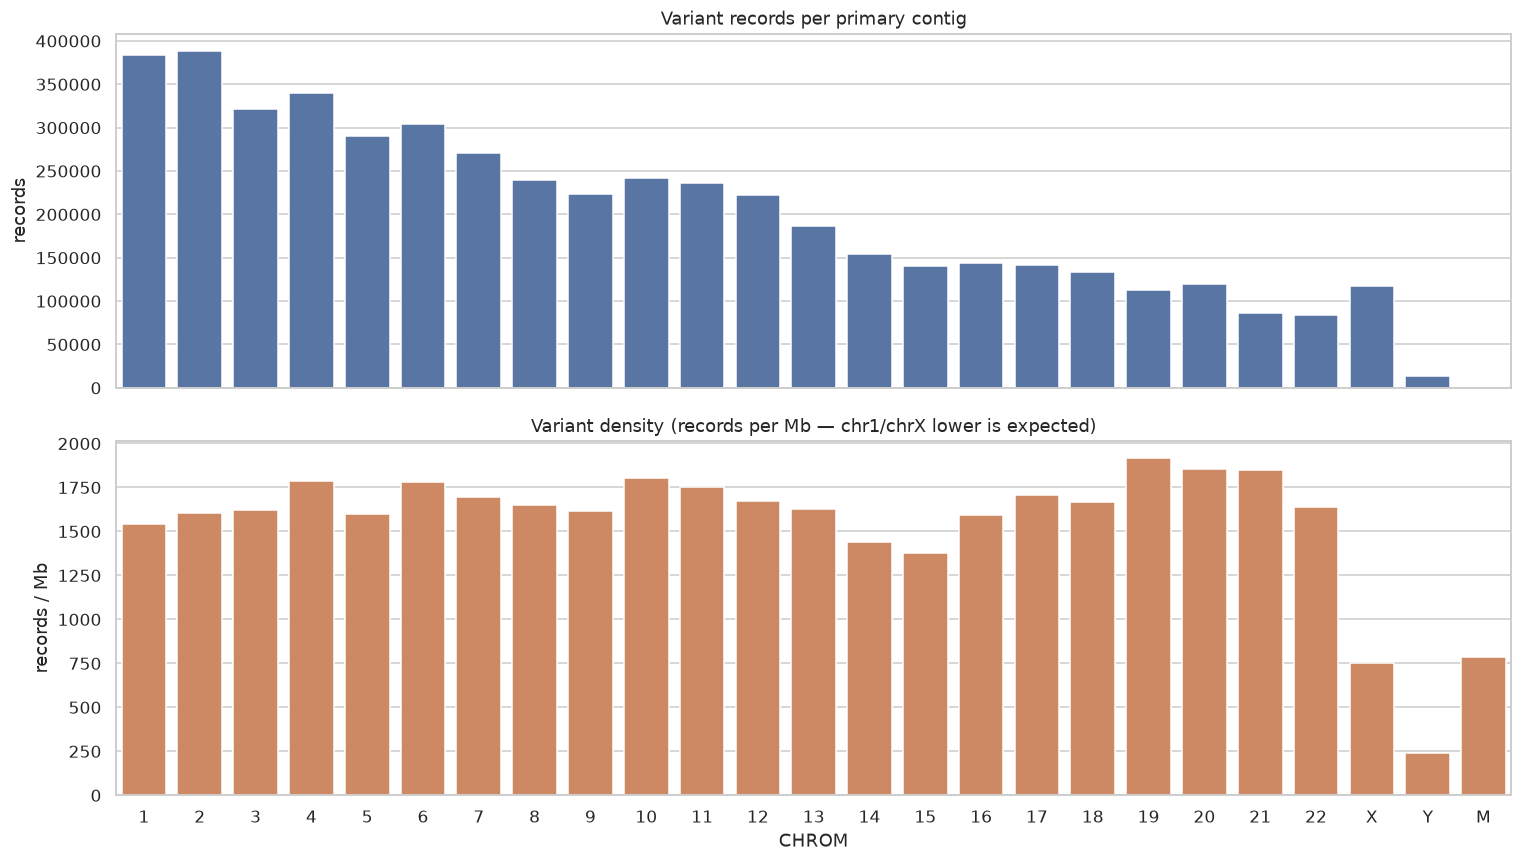

decoy/random/HLA contigs: 0 records (0.0%) — these must never outrank primary-assembly variants in ranking (cf. `src/prioritization/mva_panel.py: is_decoy_contig`).


In [11]:
primary_idx = idx[idx["assembly"] == "primary"].copy()
# numerically order 1..22 then X, Y, M
order = [str(i) for i in range(1, 23)] + ["X", "Y", "M"]
primary_idx["ord"] = primary_idx["CHROM"].map({c: i for i, c in enumerate(order)})
primary_idx = primary_idx.sort_values("ord")

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
sns.barplot(data=primary_idx, x="CHROM", y="records", ax=axes[0],
            order=primary_idx["CHROM"], color="#4c72b0")
axes[0].set_title("Variant records per primary contig")
axes[0].set_ylabel("records")

sns.barplot(data=primary_idx, x="CHROM", y="density_per_mb", ax=axes[1],
            order=primary_idx["CHROM"], color="#dd8452")
axes[1].set_title("Variant density (records per Mb — chr1/chrX lower is expected)")
axes[1].set_ylabel("records / Mb")

plt.tight_layout()
plt.show()

decoy = idx[idx["assembly"] == "decoy"]["records"].sum()
print(f"decoy/random/HLA contigs: {decoy:,} records ({decoy/stats['total']:.1%}) — "
      f"these must never outrank primary-assembly variants in ranking "
      f"(cf. `src/prioritization/mva_panel.py: is_decoy_contig`).")

## 7. Phenotype: curated HPO terms

The committed phenotypic input — 8 HPO IDs with their names parsed from inline
comments in `config/hpo_terms.yaml`. The underlying clinical document stays
local; only these de-identified ontology terms are used downstream.

In [12]:
hpo_rows = []
for line in HPO_YAML.read_text().splitlines():
    m = re.match(r'\s*-\s*"(HP:\d+)"\s*#\s*(.+)$', line)
    if m:
        term, note = m.group(1), m.group(2).strip()
        name = re.split(r"\s+[—-]\s+", note)[0]  # term name before the em-dash gloss
        hpo_rows.append({"hpo_id": term, "term": name, "note": note})

hpo = pd.DataFrame(hpo_rows)
CATEGORY = {  # coarse grouping for the plot; interpretation, not source data
    "HP:0002859": "oncology",
    "HP:0000121": "renal",
    "HP:0004322": "growth",
    "HP:0001508": "growth",
    "HP:0003202": "neuromuscular",
    "HP:0001622": "perinatal",
    "HP:0001518": "perinatal",
    "HP:0200067": "family history",
}
hpo["category"] = hpo["hpo_id"].map(CATEGORY)
assert len(hpo) == 8, f"expected 8 HPO terms, parsed {len(hpo)}"
display(hpo[["hpo_id", "term", "category"]])

print(f"\nphenotype_weight = {config['phenotype_weight']}  |  "
      f"pathogenicity_weight = {config['pathogenicity_weight']}")

,hpo_id,term,category
0,HP:0002859,Rhabdomyosarcoma,oncology
1,HP:0000121,Nephrocalcinosis,renal
2,HP:0004322,Short stature,growth
3,HP:0001508,Failure to thrive,growth
4,HP:0003202,Skeletal muscle atrophy,neuromuscular
5,HP:0001622,Premature birth,perinatal
6,HP:0001518,Small for gestational age,perinatal
7,HP:0200067,Recurrent spontaneous abortion,family history



phenotype_weight = 0.6  |  pathogenicity_weight = 0.4


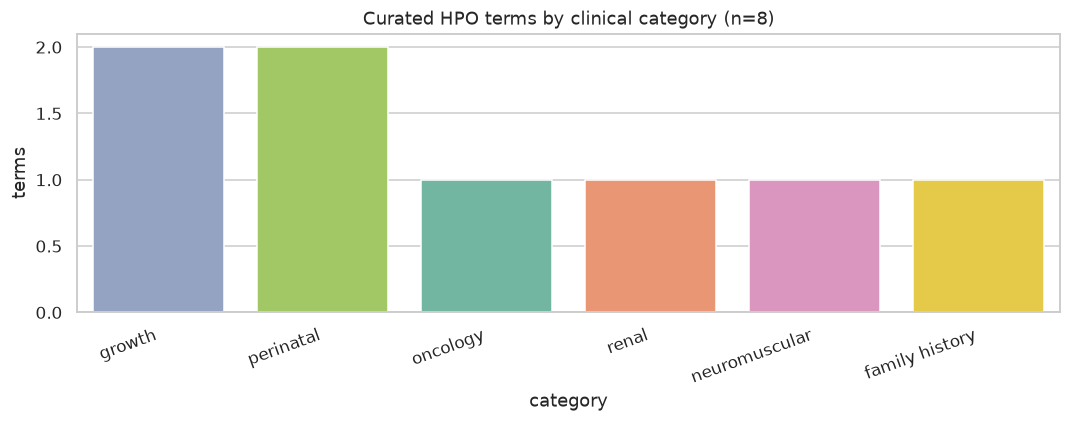

In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.countplot(data=hpo, x="category", order=hpo["category"].value_counts().index,
              hue="category", palette="Set2", legend=False, ax=ax)
ax.set_title("Curated HPO terms by clinical category (n=8)")
ax.set_ylabel("terms")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

**Finding:** the phenotype clusters into four themes — **oncology**
(rhabdomyosarcoma), **growth** (short stature, failure to thrive), **perinatal**
(premature birth, SGA) plus **renal** (nephrocalcinosis), **neuromuscular**
(skeletal muscle atrophy) and a **family-history** signal (recurrent
spontaneous abortion → chromosomal-instability hint). MVA's known mechanism —
biallelic spindle-assembly-checkpoint failure (*BUB1B*, *BUB3*, *TRIP13*,
*CEP57*) — connects all six themes, so a gene-first ranking that boosts these
intervals is biologically motivated, not answer-key leakage (the intervals are
public GRCh38 coordinates in `src/prioritization/mva_panel.py`).

## 8. Findings & implications

Numbers below are recomputed from the cells above (not hand-copied).

In [14]:
findings = {
    "VCF records": f"{stats['total']:,}",
    "SNVs": f"{types.get('SNV', 0):,} ({types.get('SNV',0)/stats['total']:.1%})",
    "indels": f"{types.get('indel', 0):,} ({types.get('indel',0)/stats['total']:.1%})",
    "multiallelic": f"{stats['multiallelic']:,}",
    "Ti/Tv": f"{titv:.3f}",
    "PASS rate": f"{combos.get('PASS', 0)/stats['total']:.1%}",
    "het/hom-alt": f"{gts.get('het',0)/max(gts.get('hom_alt',1),1):.2f}",
    "dbSNP-known": f"{stats['db_present']/stats['total']:.1%}",
    "annotation in raw VCF": "NONE — but data/interim/full.vep.vcf.gz "
                             "(VEP v113, gnomADe_AF + CLIN_SIG) now covers it",
    "remaining annotation gap": "CADD (plugin wired, not applied) + "
                                "gene↔HPO map (downloaded, not consumed)",
    "FASTQ QC": f"sampled {N_SAMPLE_READS:,} reads/file — GC "
                f"{qc['gc_pct'].min():.1f}-{qc['gc_pct'].max():.1f}% uniform, "
                f"mean Phred {qc['mean_phred'].min():.1f}, %Q30 "
                f"{qc['pct_q30'].min():.1f}%",
    "phenotype input": "8 curated HPO terms, phenotype_weight "
                       f"= {config['phenotype_weight']} (score neutral 0.5 "
                       "until gene map wired)",
}
for k, v in findings.items():
    print(f"{k:>22}: {v}")

           VCF records: 5,012,204
                  SNVs: 4,082,023 (81.4%)
                indels: 930,181 (18.6%)
          multiallelic: 66,860
                 Ti/Tv: 1.946
             PASS rate: 94.6%
           het/hom-alt: 1.64
           dbSNP-known: 88.0%
 annotation in raw VCF: NONE — but data/interim/full.vep.vcf.gz (VEP v113, gnomADe_AF + CLIN_SIG) now covers it
remaining annotation gap: CADD (plugin wired, not applied) + gene↔HPO map (downloaded, not consumed)
              FASTQ QC: sampled 50,000 reads/file — GC 41.1-41.7% uniform, mean Phred 35.1, %Q30 89.4%
       phenotype input: 8 curated HPO terms, phenotype_weight = 0.6 (score neutral 0.5 until gene map wired)


### What this EDA changes for the prioritization step

1. **Annotation: the raw-input gap is closed; two joins remain.** The raw VCF
   has zero consequence/frequency columns, but `data/interim/full.vep.vcf.gz`
   (same 5,012,204 records) now carries VEP `CSQ` with gnomADe AF + ClinVar
   `CLIN_SIG`. Still missing from the scoring path: **CADD** (files present,
   `--plugin CADD` wired in `src/annotation/vep.py`, not yet applied to the
   interim VCF) and the **gene↔HPO map** (`data/hpo/genes_to_phenotype.txt`
   present; `prioritize.py` still calls `hpo_overlap_score(..., gene_hpo_map=
   None)` → phenotype_score is neutral 0.5 for every non-panel gene).
2. **Quality metrics are usable immediately** (`QD`, `MQ`, `DP`, `QUAL`, `DB`)
   and 5.4% of records fail ≥1 GATK filter (94.6% PASS) — passing-only is a
   cheap first cut before scoring.
3. **2.3% of records (116,485) sit on decoy/random/HLA contigs** and must be
   demoted (already handled by `mva_panel.is_decoy_contig`).
4. **Novel/rare signal** lives in the ~12% of records absent from dbSNP; with
   gnomADe AF now in `CSQ`, `AF < 0.01` (config) becomes a real rarity gate —
   the earlier ranked output's empty `gnomad_af` column predates the interim
   VCF and should be re-run against it.
5. **Phenotype enters as 6 clinical themes** with weight 0.6 — wiring
   `genes_to_phenotype.txt` into `hpo_overlap_score` is the highest-leverage
   fix for the currently-flat phenotype term.

→ Next: `notebooks/02_variant_prioritization` (feature integration + ranking
prototype), then the Track 1 report (`reports/track1_template.md`).